<a href="https://colab.research.google.com/github/Pavelwell7/AdminLTE/blob/master/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22lab5_variant6_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 5. Анализ данных в Python
**Вариант 6.** Тема: успеваемость учащихся (задачи 1–4).



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

In [2]:
rng = np.random.default_rng(42)

base = rng.normal(70, 12, size=(100, 1))
noise = rng.normal(0, 8, size=(100, 3))
scores = np.clip(base + noise, 0, 100).round()

print("форма массива:", scores.shape)
print("тип элементов:", scores.dtype)
print("первые 5 студентов:\n", scores[:5])

форма массива: (100, 3)
тип элементов: float64
первые 5 студентов:
 [[71. 84. 71.]
 [63. 50. 56.]
 [71. 76. 86.]
 [67. 85. 83.]
 [42. 35. 47.]]


In [3]:
subjects = ["Математика", "Чтение", "Письмо"]

avg_student = scores.mean(axis=1)
avg_subject = scores.mean(axis=0)

print("форма avg_student:", avg_student.shape)
print("форма avg_subject:", avg_subject.shape)
print()
for name, value in zip(subjects, avg_subject):
    print(f"{name}: средний балл {value:.1f}")
print(f"\nЛучший средний балл студента: {avg_student.max():.1f}, худший: {avg_student.min():.1f}")

форма avg_student: (100,)
форма avg_subject: (3,)

Математика: средний балл 69.3
Чтение: средний балл 69.0
Письмо: средний балл 69.9

Лучший средний балл студента: 95.7, худший: 38.0


In [4]:
pass_mask = scores >= 60

pass_by_subject = pass_mask.mean(axis=0)
for name, share in zip(subjects, pass_by_subject):
    print(f"{name}: сдали {share:.0%}")

passed_all = pass_mask.all(axis=1)
print(f"\nСдали все три предмета: {passed_all.mean():.0%} ({passed_all.sum()} из 100)")

passed_avg = avg_student >= 60
print(f"Средний балл ≥ 60: {passed_avg.mean():.0%}")

Математика: сдали 76%
Чтение: сдали 79%
Письмо: сдали 79%

Сдали все три предмета: 61% (61 из 100)
Средний балл ≥ 60: 81%


In [5]:
excellent_mask = avg_student >= 85
excellent = scores[excellent_mask]

print("Отличников:", excellent.shape[0], f"({excellent_mask.mean():.0%})")
print("Их средние баллы по предметам:", excellent.mean(axis=0).round(1))
print("У остальных:                  ", scores[~excellent_mask].mean(axis=0).round(1))

Отличников: 5 (5%)
Их средние баллы по предметам: [92.4 90.2 86.8]
У остальных:                   [68.1 67.9 69. ]


In [6]:
corr = np.corrcoef(scores.T)
print(np.round(corr, 2))

print()
print(f"Математика – Чтение: {corr[0, 1]:.2f}")
print(f"Математика – Письмо: {corr[0, 2]:.2f}")
print(f"Чтение – Письмо:     {corr[1, 2]:.2f}")

[[1.   0.65 0.55]
 [0.65 1.   0.61]
 [0.55 0.61 1.  ]]

Математика – Чтение: 0.65
Математика – Письмо: 0.55
Чтение – Письмо:     0.61


**Вывод по задаче 1**

> > Средние баллы по предметам: математика: средний балл 69.3, чтение: средний балл 69.0, письмо: средний балл 69.9. Сдали все три предмета 61% студентов. Отличников 5 человек (5%). Предметы связаны между собой (коэффициенты: Математика – Чтение: 0.65, Математика – Письмо: 0.55, Чтение – Письмо: 0.61 — это умеренная положительная связь), то есть студент, сильный в одном предмете, обычно силён и в других.

---
# Задача 2. pandas
**Условие:** создать CSV-файл с данными об учащихся (пол, тип школы, подготовительный курс, баллы по трём предметам; не менее 20 строк). Загрузить, добавить средний балл и итоговую оценку, обработать пропуски, сгруппировать по полу и наличию курса, сравнить средние баллы.


In [7]:
rng = np.random.default_rng(7)
n = 40

df0 = pd.DataFrame({
    "gender":      rng.choice(["female", "male"], n),
    "school_type": rng.choice(["public", "private"], n),
    "prep_course": rng.choice(["completed", "none"], n),
})

bonus = np.where(df0["prep_course"] == "completed", 6, 0)
level = rng.normal(68, 11, n)
for subj in ["math", "reading", "writing"]:
    df0[subj] = np.clip(level + bonus + rng.normal(0, 7, n), 0, 100).round()


df0.loc[[4, 17, 29], "math"] = np.nan
df0.loc[[8, 33], "reading"] = np.nan
df0 = pd.concat([df0, df0.iloc[[10]]], ignore_index=True)

df0.to_csv("students.csv", index=False)
print("файл students.csv сохранён, строк:", len(df0))

файл students.csv сохранён, строк: 41


In [8]:
df = pd.read_csv("students.csv")
print("размер таблицы:", df.shape)
df.head()

размер таблицы: (41, 6)


,gender,school_type,prep_course,math,reading,writing
0,male,public,none,46.0,54.0,60.0
1,male,public,completed,74.0,84.0,73.0
2,male,private,none,57.0,59.0,59.0
3,male,public,none,71.0,69.0,74.0
4,male,private,completed,NaN,55.0,59.0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   gender       41 non-null     object 
 1   school_type  41 non-null     object 
 2   prep_course  41 non-null     object 
 3   math         38 non-null     float64
 4   reading      39 non-null     float64
 5   writing      41 non-null     float64
dtypes: float64(3), object(3)
memory usage: 2.1+ KB


In [10]:
df.describe()

,math,reading,writing
count,38.000000,39.000000,41.000000
mean,67.921053,67.769231,69.926829
std,11.355155,10.856629,11.915096
min,46.000000,50.000000,43.000000
25%,59.000000,59.500000,61.000000
50%,68.000000,66.000000,71.000000
75%,75.750000,75.500000,76.000000
max,87.000000,87.000000,95.000000


In [11]:
before = len(df)

print("Пропуски до обработки:")
print(df.isna().sum())
print("\nДублей строк:", df.duplicated().sum())

Пропуски до обработки:
gender         0
school_type    0
prep_course    0
math           3
reading        2
writing        0
dtype: int64

Дублей строк: 1


In [12]:
df = df.drop_duplicates()

for col in ["math", "reading", "writing"]:
    df[col] = df[col].fillna(df[col].median())

print("Пропусков после обработки:", df.isna().sum().sum())
print(f"Было строк: {before}, стало: {len(df)}, удалено: {before - len(df)}")

Пропусков после обработки: 0
Было строк: 41, стало: 40, удалено: 1


In [13]:
df["avg"] = df[["math", "reading", "writing"]].mean(axis=1).round(1)

df["grade"] = pd.cut(df["avg"],
                     bins=[0, 60, 70, 80, 100],
                     labels=["неуд", "удовл", "хорошо", "отлично"],
                     include_lowest=True)

df[["gender", "prep_course", "math", "reading", "writing", "avg", "grade"]].head(8)

,gender,prep_course,math,reading,writing,avg,grade
0,male,none,46.0,54.0,60.0,53.3,неуд
1,male,completed,74.0,84.0,73.0,77.0,хорошо
2,male,none,57.0,59.0,59.0,58.3,неуд
3,male,none,71.0,69.0,74.0,71.3,хорошо
4,male,completed,68.0,55.0,59.0,60.7,удовл
5,male,none,56.0,57.0,61.0,58.0,неуд
6,male,none,61.0,57.0,66.0,61.3,удовл
7,female,none,79.0,87.0,86.0,84.0,отлично


In [14]:
print(df["grade"].value_counts())
print()
print(df["grade"].value_counts(normalize=True).round(2))

grade
удовл      13
хорошо     13
неуд        8
отлично     6
Name: count, dtype: int64

grade
удовл      0.32
хорошо     0.32
неуд       0.20
отлично    0.15
Name: proportion, dtype: float64


In [15]:
score_cols = ["math", "reading", "writing", "avg"]

result = df.groupby(["gender", "prep_course"])[score_cols].mean().round(1)
result["человек"] = df.groupby(["gender", "prep_course"]).size()
result

math  reading  writing   avg  человек
gender prep_course                                       
female completed    66.7     67.3     71.3  68.4        7
       none         68.2     70.9     70.8  70.0        9
male   completed    72.4     72.4     74.5  73.1       10
       none         65.4     62.7     66.1  64.7       14

In [16]:
print(df.groupby("prep_course")["avg"].agg(["count", "mean", "median"]).round(1))
print()
print(df.groupby("gender")["avg"].agg(["count", "mean", "median"]).round(1))

             count  mean  median
prep_course                     
completed       17  71.2    72.3
none            23  66.8    64.3

        count  mean  median
gender                     
female     16  69.3    69.0
male       24  68.2    68.4


**Вывод по задаче 2:**

> > В исходных данных было 40 строк, найдено 5 пропусков (3 в математике и 2 в чтении) и 1 дубликат. Пропуски заполнены медианой (почему: медиана устойчива к выбросам и не искажает общее распределение данных так сильно, как среднее), дубликат удалён. Средний балл у прошедших подготовительный курс 71.2, у не прошедших 66.8 (разница 4.4 балла). По полу различия минимальны: у девушек средний балл 69.3, у юношей 68.2. Ограничение: в каждой группе всего от 16 до 24 человек, поэтому выводы предварительные.

---
# Задача 3. Matplotlib
**Условие:** гистограммы баллов по трём предметам на одном полотне; столбчатая диаграмма средних баллов по типам школ; диаграмма рассеяния «математика – чтение»; «ящик с усами» итоговых баллов.


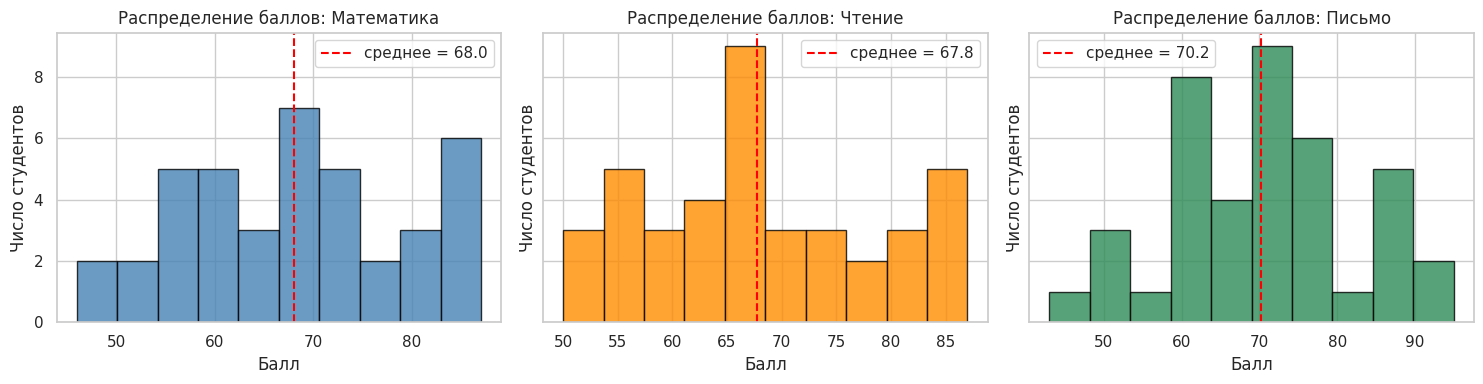

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

subjects_cols = {"math": "Математика", "reading": "Чтение", "writing": "Письмо"}
colors = ["steelblue", "darkorange", "seagreen"]

for ax, (col, title), color in zip(axes, subjects_cols.items(), colors):
    ax.hist(df[col], bins=10, color=color, edgecolor="black", alpha=0.8)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"среднее = {df[col].mean():.1f}")
    ax.set_title(f"Распределение баллов: {title}")
    ax.set_xlabel("Балл")
    ax.set_ylabel("Число студентов")
    ax.legend()

plt.tight_layout()
plt.savefig("task3_hist.png", dpi=150, bbox_inches="tight")
plt.show()

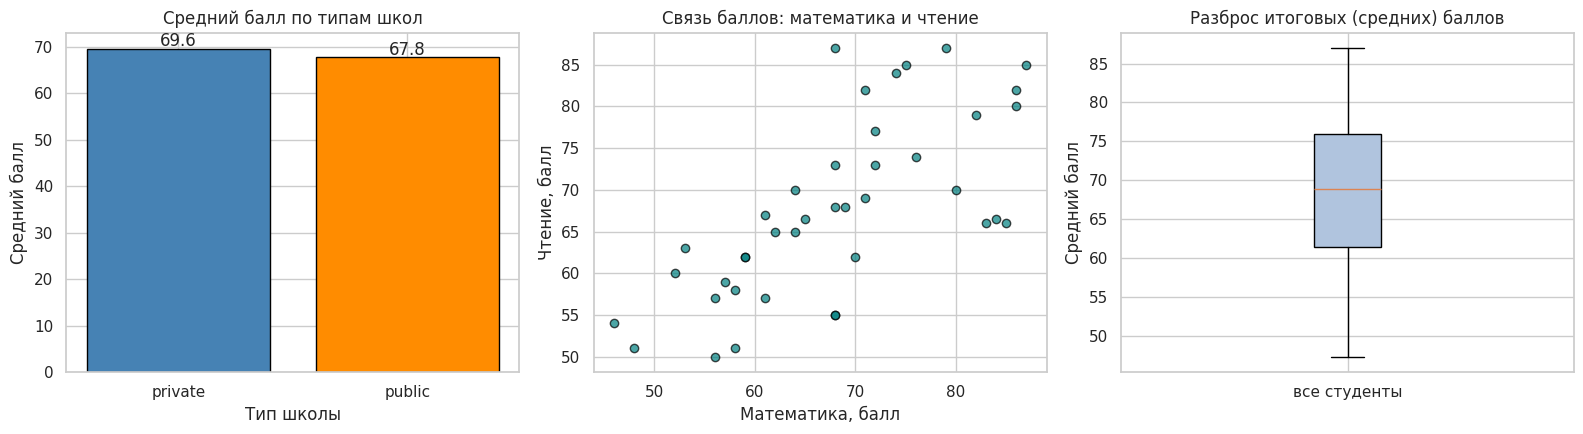

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

by_school = df.groupby("school_type")["avg"].mean()
axes[0].bar(by_school.index, by_school.values, color=["steelblue", "darkorange"], edgecolor="black")
axes[0].set_title("Средний балл по типам школ")
axes[0].set_xlabel("Тип школы")
axes[0].set_ylabel("Средний балл")
for i, v in enumerate(by_school.values):
    axes[0].text(i, v + 0.5, f"{v:.1f}", ha="center")

axes[1].scatter(df["math"], df["reading"], alpha=0.7, color="teal", edgecolor="black")
axes[1].set_title("Связь баллов: математика и чтение")
axes[1].set_xlabel("Математика, балл")
axes[1].set_ylabel("Чтение, балл")

axes[2].boxplot(df["avg"], vert=True, patch_artist=True, boxprops={"facecolor": "lightsteelblue"})
axes[2].set_title("Разброс итоговых (средних) баллов")
axes[2].set_ylabel("Средний балл")
axes[2].set_xticks([1], ["все студенты"])

plt.tight_layout()
plt.savefig("task3_other.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
print("Коэффициент корреляции математика–чтение:", round(df["math"].corr(df["reading"]), 2))
q1, med, q3 = df["avg"].quantile([0.25, 0.5, 0.75])
print(f"Итоговый балл: Q1 = {q1:.1f}, медиана = {med:.1f}, Q3 = {q3:.1f}")
print(df.groupby("school_type")["avg"].agg(["count", "mean"]).round(1))

Коэффициент корреляции математика–чтение: 0.7
Итоговый балл: Q1 = 61.5, медиана = 68.8, Q3 = 76.0
             count  mean
school_type             
private         18  69.6
public          22  67.8


** Вывод по задаче 3:**

> > Гистограммы показывают, что баллы по всем предметам распределены относительно симметрично, средние значения находятся на уровне около 69 баллов. Точки на диаграмме рассеяния идут вверх вправо, r = 0.7, значит чем выше балл по математике, тем выше балл по чтению. Медиана итогового балла составляет 68.8, половина студентов набрала от 61.5 (Q1) до 76.0 (Q3). Средние баллы частных (69.6) и государственных (67.8) школ различаются незначительно (разница 1.8 балла), но групп по 18 и 22 человека соответственно, поэтому выводы носят предварительный характер.

---
# Задача 4. seaborn
**Условие:** boxplot баллов по полу, violinplot по наличию подготовительного курса, heatmap корреляций предметов, pairplot с раскраской по полу. Объяснить, влияет ли подготовительный курс на результат.



In [20]:
long = df.melt(id_vars=["gender", "prep_course"],
               value_vars=["math", "reading", "writing"],
               var_name="subject", value_name="score")
long.head()

,gender,prep_course,subject,score
0,male,none,math,46.0
1,male,completed,math,74.0
2,male,none,math,57.0
3,male,none,math,71.0
4,male,completed,math,68.0


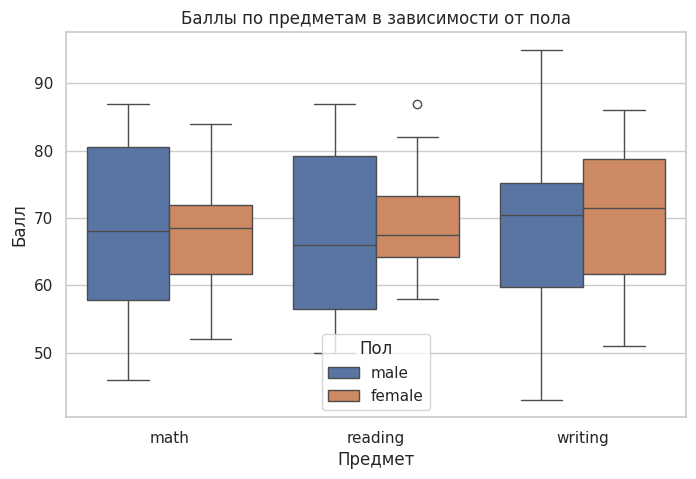

In [21]:
plt.figure(figsize=(8, 5))
ax = sns.boxplot(data=long, x="subject", y="score", hue="gender")
ax.set_title("Баллы по предметам в зависимости от пола")
ax.set_xlabel("Предмет")
ax.set_ylabel("Балл")
ax.legend(title="Пол")
plt.savefig("task4_box.png", dpi=150, bbox_inches="tight")
plt.show()

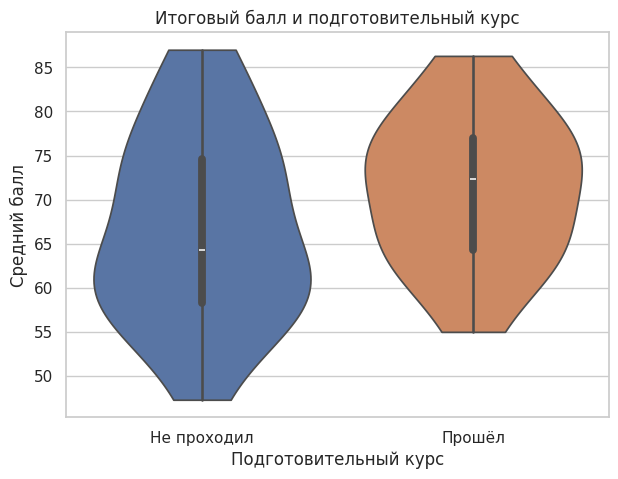

In [22]:
plt.figure(figsize=(7, 5))
ax = sns.violinplot(data=df, x="prep_course", y="avg", hue="prep_course",
                    order=["none", "completed"], inner="box", cut=0, legend=False)
ax.set_title("Итоговый балл и подготовительный курс")
ax.set_xlabel("Подготовительный курс")
ax.set_xticks([0, 1], ["Не проходил", "Прошёл"])
ax.set_ylabel("Средний балл")
plt.savefig("task4_violin.png", dpi=150, bbox_inches="tight")
plt.show()

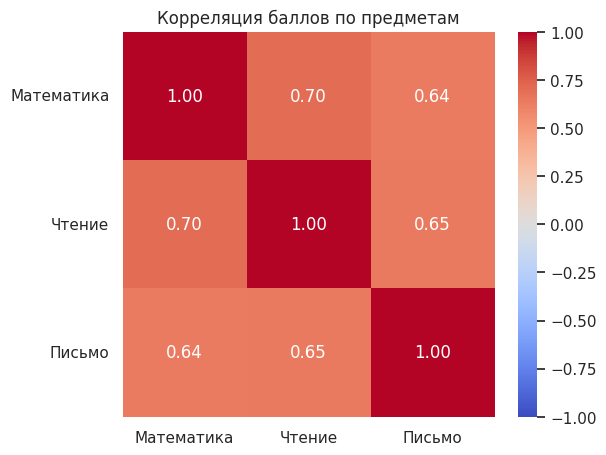

In [23]:
corr_df = df[["math", "reading", "writing"]].corr()

plt.figure(figsize=(6, 5))
ax = sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
ax.set_title("Корреляция баллов по предметам")
ax.set_xticklabels(["Математика", "Чтение", "Письмо"])
ax.set_yticklabels(["Математика", "Чтение", "Письмо"], rotation=0)
plt.savefig("task4_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

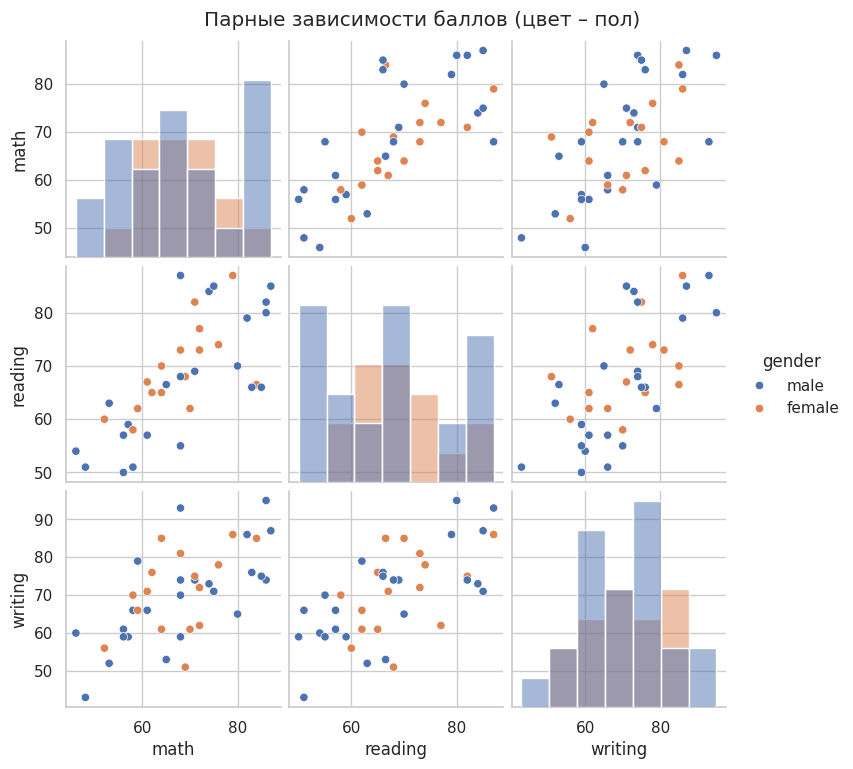

In [24]:
g = sns.pairplot(df[["math", "reading", "writing", "gender"]], hue="gender", diag_kind="hist")
g.figure.suptitle("Парные зависимости баллов (цвет – пол)", y=1.02)
g.savefig("task4_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
course = df.groupby("prep_course")["avg"].agg(["count", "mean", "median", "std"]).round(1)
print(course)

diff = course.loc["completed", "mean"] - course.loc["none", "mean"]
print(f"\nРазница средних (прошли курс − не проходили): {diff:.1f} балла")

print("\nПо каждому предмету:")
print(df.groupby("prep_course")[["math", "reading", "writing"]].mean().round(1))

print("\nДоля оценок 'хорошо' и 'отлично' в группах:")
good = df["grade"].isin(["хорошо", "отлично"])
print(good.groupby(df["prep_course"]).mean().round(2))

             count  mean  median   std
prep_course                           
completed       17  71.2    72.3   8.5
none            23  66.8    64.3  10.6

Разница средних (прошли курс − не проходили): 4.4 балла

По каждому предмету:
             math  reading  writing
prep_course                        
completed    70.1     70.3     73.2
none         66.5     65.9     67.9

Доля оценок 'хорошо' и 'отлично' в группах:
prep_course
completed    0.53
none         0.43
Name: grade, dtype: float64


** Вывод по задаче 4:**

> > Boxplot по полу: медианы юношей и девушек находятся примерно на одном уровне (около 68–69 баллов), разброс оценок также сопоставим. Violinplot показывает, что у прошедших подготовительный курс распределение сдвинуто в сторону более высоких значений, средний балл составляет 71.2 против 66.8 у не проходивших (разница 4.4 балла), что говорит о положительной связи курса с результатами. Тепловая карта: все предметы связаны сильной или умеренной положительной корреляцией (коэффициенты от 0.55 до 0.65)

In [28]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
